# SILLA — 03 · Meal Cost Prediction (experiment)
**Owner:** Amr Badr · Data Science & Recommendation
**تجربة نموذج لتوقع تكلفة الوجبة**

**Goal:** predict a dish's cost per serving from *what the recipe is* — ingredient list, category, cuisine, time,
difficulty — without looking up the price list. This is useful for new recipes or recipes with missing product prices.

- **Target:** estimated cost per serving (EGP) from `data_loader` (real prices + imputation).
- **Features:** binary ingredient presence, ingredient-category counts, category, cuisine, servings, time, difficulty, number of ingredients.
  *Quantities are not used on purpose — with quantities the model would simply re-learn the price list.*
- **Rows:** 155 unique dishes (style variants removed — they are exact duplicates).
- **Validation:** 5-fold cross-validation repeated 3 times; metrics on the original EGP scale.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "SILLA_Data_Engineering").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from SILLA_Data_Science.data_loader import FIGURES_DIR, build_recipe_table, load_tables, unique_recipes

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

# Chart style: one accent colour, quiet axes, light grid
ACCENT, ACCENT_2, ACCENT_3, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

In [2]:
from sklearn.model_selection import RepeatedKFold
from SILLA_Data_Science.cost_model import build_features, cross_validate, leakage_demo, feature_importance, oof_predictions, SEED
tables = load_tables()
recipes_all = build_recipe_table(); recipes = unique_recipes(recipes_all)
X, y = build_features(recipes, tables)
print(f"Dishes: {len(X)} | features: {X.shape[1]} | target mean {y.mean():.1f} EGP, median {y.median():.1f} EGP")

Dishes: 155 | features: 179 | target mean 48.1 EGP, median 40.3 EGP


In [3]:
cv = cross_validate(X, y, RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED))
cv = pd.DataFrame(cv).T
cv.round(3)

,MAE_egp,RMSE_egp,R2,MedianAPE_pct,within_25pct,R2_std
Baseline: category median,18.144,24.050,0.542,38.315,0.350,0.138
Ridge regression (log target),16.368,24.084,0.551,31.877,0.413,0.180
Random forest,13.031,18.524,0.731,25.554,0.507,0.071
Gradient boosting,12.576,17.546,0.761,25.380,0.488,0.069


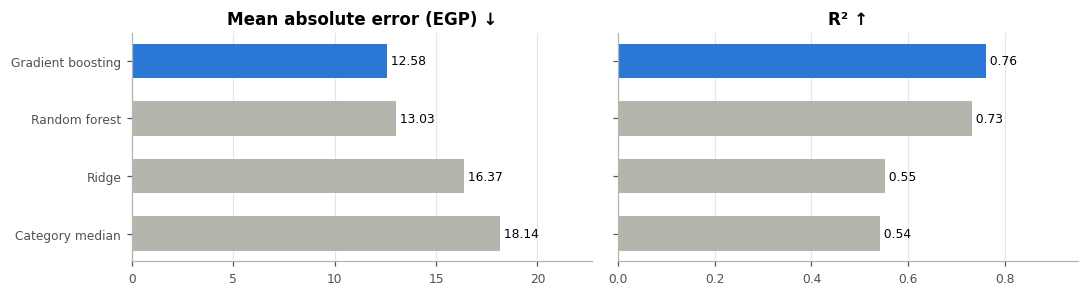

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
names = {"Baseline: category median": "Category median", "Ridge regression (log target)": "Ridge",
         "Random forest": "Random forest", "Gradient boosting": "Gradient boosting"}
for ax, (m, t) in zip(axes, [("MAE_egp", "Mean absolute error (EGP) ↓"), ("R2", "R² ↑")]):
    v = cv[m].rename(index=names)
    best = v.idxmin() if m == "MAE_egp" else v.idxmax()
    ax.barh(v.index, v.values, color=[ACCENT if i == best else "#b5b4ad" for i in v.index], height=0.6)
    for yy, val in enumerate(v.values): ax.text(val, yy, f" {val:.2f}", va="center", fontsize=8)
    ax.set_title(t); ax.grid(axis="y", visible=False); ax.set_xlim(0, v.max() * 1.25)
save(fig, "cost_model_comparison")

## Why duplicates must be removed (leakage check)
If the 320 rows are split randomly, a style variant can sit in the training set while its identical twin is in the test
set — the model just "remembers" the answer. Grouping by dish family gives the honest estimate.

In [5]:
leakage_demo(recipes_all, tables).round(3)

,MAE_egp,RMSE_egp,R2,MedianAPE_pct,within_25pct
KFold on 320 rows (variants leak),7.922,11.819,0.897,12.906,0.728
GroupKFold by dish family (correct),13.448,18.830,0.733,25.820,0.484


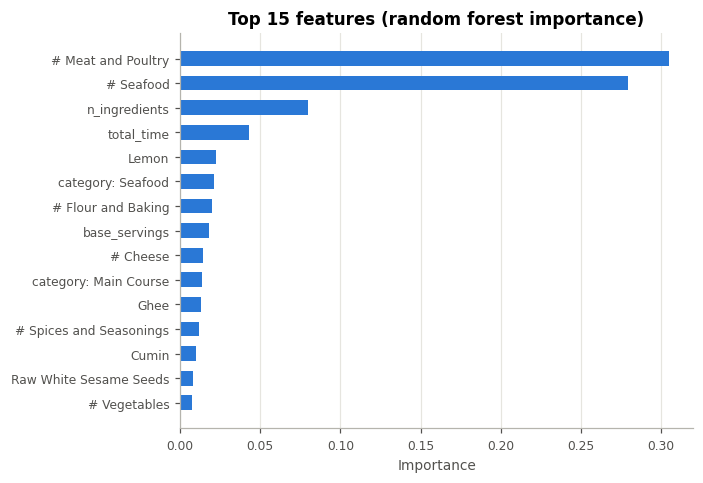

In [6]:
fi = feature_importance(X, y, top=15).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(fi.index.str.replace("n_cat_", "# ").str.replace("ing_", "").str.replace("category_", "category: "),
        fi.values, color=ACCENT, height=0.6)
ax.grid(axis="y", visible=False); ax.set(title="Top 15 features (random forest importance)", xlabel="Importance")
save(fig, "cost_feature_importance")

,recipe_name_en,category,actual,predicted
recipe_id,,,,
R0120,Grilled Mullet With Wheat Bran (Bouri Bil-Radda),Seafood,147.05,75.8
R0038,Egyptian Beef Escalope Pane,Main Course,104.51,51.1
R0019,Singari Sea Bass Alexandrian Style,Seafood,199.73,149.5
R0131,Penne With Tuna And Tomato Sauce,Main Course,47.60,94.9
R0067,Fried Meat Kibbeh,Main Course,100.95,58.5
R0123,Crispy Fried Alexandrian Calamari,Seafood,96.74,136.4


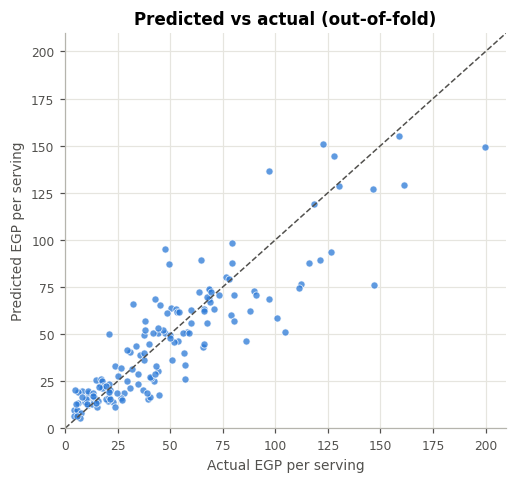

In [7]:
pred = oof_predictions(X, y, "Gradient boosting")
fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.scatter(y, pred, s=22, color=ACCENT, alpha=0.75, edgecolor="white", linewidth=0.6)
lim = [0, max(y.max(), pred.max()) * 1.05]
ax.plot(lim, lim, color=MUTED, ls="--", lw=1); ax.set(xlim=lim, ylim=lim)
ax.set(title="Predicted vs actual (out-of-fold)", xlabel="Actual EGP per serving", ylabel="Predicted EGP per serving")
save(fig, "cost_pred_vs_actual")
err = (pred - y).rename("error")
worst = recipes.set_index("recipe_id").loc[err.abs().nlargest(6).index, ["recipe_name_en", "category"]]
worst.assign(actual=y, predicted=pred.round(1))

## Conclusions — is the data sufficient?
- **Partly.** Gradient boosting / random forest explain about **75% of the variance** (R² ≈ 0.73–0.76) with a typical error of
  ≈ 12–13 EGP per serving, clearly better than the category-median baseline (R² ≈ 0.54) and linear Ridge.
- **Protein is the signal:** the number of meat/poultry and seafood ingredients dominates the importance ranking.
- **Leakage matters:** with duplicate variants left in, the same model would report R² ≈ 0.90 — an over-optimistic number.
- **Not production-ready:** only 155 dishes, ~half of predictions are within ±25%, and the target itself is partly imputed.
  Use it as a rough estimate for *new* recipes (e.g. "≈ 40–60 EGP per serving"), while existing recipes should keep using the
  exact cost calculator. More recipes and fuller price coverage are needed before relying on it.